In [5]:
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print(path)

C:\Users\USER\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2


In [6]:
from pathlib import Path

dataset_path = Path(path)

print("Dataset exists:", dataset_path.exists())
print("\nContents of the dataset:")

for item in dataset_path.iterdir():
    print(item.name)


Dataset exists: True

Contents of the dataset:
chest_xray


In [7]:
DATA_DIR = dataset_path / "chest_xray"

print("Data directory:", DATA_DIR)
print("Directory exists:", DATA_DIR.exists())

for i in DATA_DIR.iterdir():
    print(i.name)

Data directory: C:\Users\USER\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray
Directory exists: True
chest_xray
test
train
val
__MACOSX


In [8]:
for split in ["train", "val", "test"]:
    split_path= DATA_DIR / split
    
    print(f"\n{split.upper()}")
    
    for item in split_path.iterdir(): #list the contents of each folder
        print("", item.name)


TRAIN
 NORMAL
 PNEUMONIA

VAL
 NORMAL
 PNEUMONIA

TEST
 NORMAL
 PNEUMONIA


In [9]:
classes = ["NORMAL", "PNEUMONIA"]

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    
    for class_name in classes:
        folder = DATA_DIR / split / class_name #build the path to one class folder
        
        image_files = [
            file for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
        ]
        
        print(f"{class_name}: {len(image_files)} images")


TRAIN


NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL
NORMAL: 8 images
PNEUMONIA: 8 images

TEST
NORMAL: 234 images
PNEUMONIA: 390 images


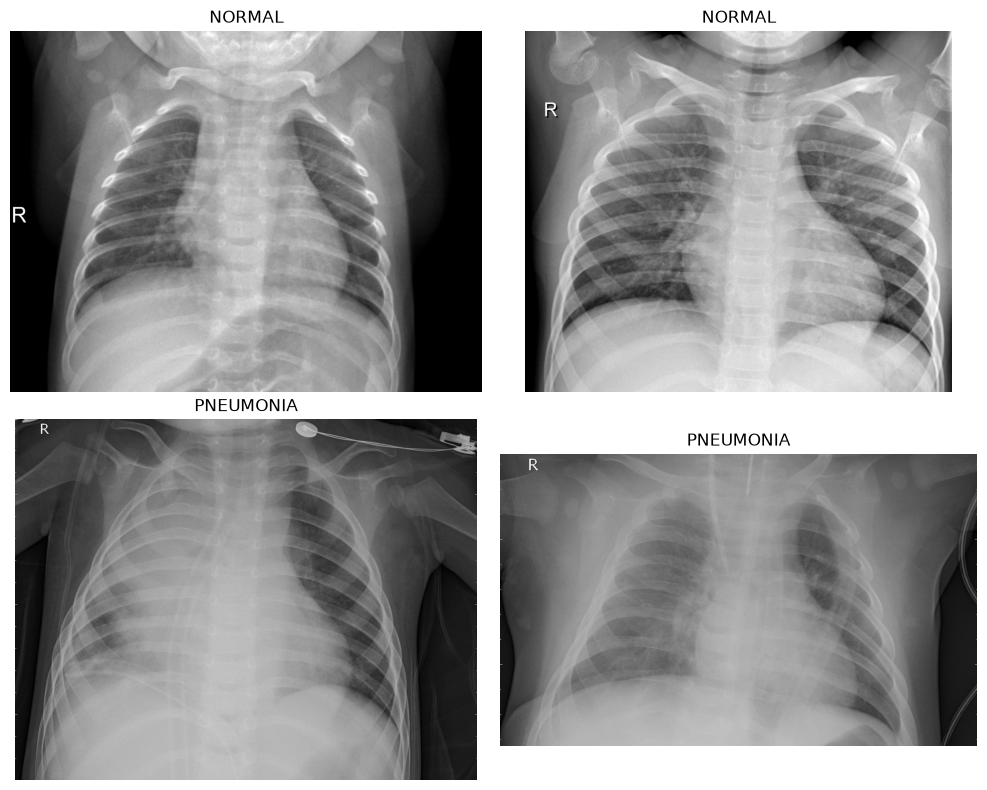

In [10]:
from PIL import Image
import matplotlib.pyplot as plt
import random

#select the training folder for each class
normal_folder = DATA_DIR / "train" / "NORMAL"
pneumonia_folder = DATA_DIR / "train" / "PNEUMONIA"

#to select 2 random images from each class
normal_images = list(normal_folder.glob("*"))
pneumonia_images = list(pneumonia_folder.glob("*"))

selected_images = (
    random.sample(normal_images,2)
    + random.sample(pneumonia_images,2)
)

#display the images
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, image_path in zip(axes.flat, selected_images):
    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(image_path.parent.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
for image_path in selected_images:
    with Image.open(image_path) as img:
        print(
            "Class:", image_path.parent.name,
            "| Size:", img.size,
            "| Mode:", img.mode
        )


Class: NORMAL | Size: (1372, 1047) | Mode: L
Class: NORMAL | Size: (1860, 1569) | Mode: L
Class: PNEUMONIA | Size: (1312, 1024) | Mode: L
Class: PNEUMONIA | Size: (1192, 728) | Mode: L


In [12]:
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = [
    path for path in DATA_DIR.rglob("*")#searches for files inside all subfolders
    if path.is_file() and path.suffix.lower() in image_extensions
]

sizes = Counter()
modes = Counter()
unreadable_images = []

for image_path in image_paths:
    try:
        with Image.open(image_path) as img:
            img.verify()

        # Reopen the image to inspect its properties
        with Image.open(image_path) as img:
            sizes[img.size] += 1
            modes[img.mode] += 1

    except Exception:
        unreadable_images.append(image_path)

print("Total image files:", len(image_paths))
print("Readable images:", len(image_paths) - len(unreadable_images))
print("Unreadable images:", len(unreadable_images))

print("\nImage dimensions:")
for size, count in sizes.most_common():
    print(size, ":", count)

print("\nImage modes:")
for mode, count in modes.items():
    print(mode, ":", count)

if unreadable_images:
    print("\nUnreadable image paths:")
    for path in unreadable_images:
        print(path)


Total image files: 17568
Readable images: 11712
Unreadable images: 5856

Image dimensions:
(1008, 704) : 14
(1072, 648) : 14
(992, 592) : 12
(992, 608) : 12
(1216, 872) : 12
(1080, 728) : 12
(1136, 680) : 10
(1160, 736) : 10
(1000, 704) : 10
(1184, 792) : 10
(1008, 600) : 10
(1192, 760) : 10
(1088, 712) : 10
(1304, 968) : 10
(1008, 680) : 10
(976, 672) : 10
(1064, 760) : 10
(1152, 664) : 10
(952, 624) : 8
(1000, 744) : 8
(1112, 736) : 8
(992, 600) : 8
(984, 520) : 8
(976, 608) : 8
(1080, 720) : 8
(904, 576) : 8
(1016, 648) : 8
(984, 672) : 8
(1008, 728) : 8
(1152, 832) : 8
(968, 656) : 8
(1120, 680) : 8
(952, 664) : 8
(1168, 840) : 8
(1080, 752) : 8
(1152, 728) : 8
(1032, 744) : 8
(952, 632) : 8
(1008, 696) : 8
(1152, 672) : 8
(1072, 664) : 8
(1016, 680) : 8
(1152, 736) : 8
(1160, 752) : 8
(1136, 688) : 8
(1128, 752) : 8
(1160, 800) : 8
(1000, 624) : 8
(1064, 632) : 8
(1184, 808) : 8
(968, 576) : 8
(1064, 592) : 8
(984, 656) : 8
(1000, 568) : 8
(920, 544) : 8
(1128, 736) : 8
(1176, 760

In [13]:
class_counts = Counter()

for image_path in image_paths:
    if image_path not in unreadable_images:
        class_name = image_path.parent.name
        
        if class_name in ["NORMAL", "PNEUMONIA"]:
            class_counts[class_name] += 1
            
print("Class distribution :")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count} images")

Class distribution :
NORMAL: 3166 images
PNEUMONIA: 8546 images


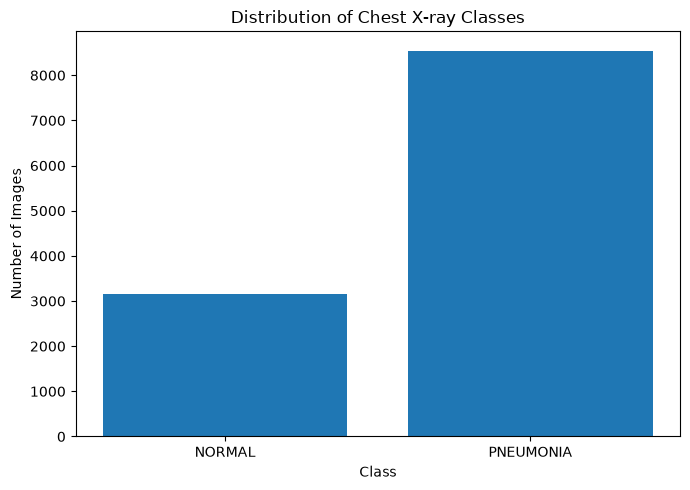

In [14]:
plt.figure(figsize=(7, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("Distribution of Chest X-ray Classes")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()


In [15]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

In [ ]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary",
    validation_split=0.2,
    subset="training",
    seed=SEED
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary",
    validation_split=0.2,
    subset="validation",
    seed=SEED
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary",
    shuffle=False
)

print("Classes:", train_ds_raw.class_names)
print("Image size:", IMG_SIZE)


Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']
Image size: (180, 180)


In [17]:
def normalize_images(images, labels):
    images = tf.cast(images, tf.float32) / 255
    return images, labels

train_ds = train_ds_raw.map(normalize_images)
val_ds = val_ds_raw.map(normalize_images)
test_ds = test_ds_raw.map(normalize_images)

Batch shape: (32, 180, 180, 3)
Labels shape: (32, 1)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0


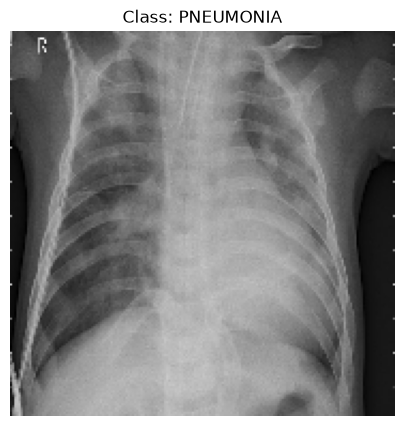

In [ ]:
images, labels = next(iter(train_ds))

print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Data type:", images.dtype)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))

plt.figure(figsize=(5, 5))
plt.imshow(images[0].numpy())
plt.title(
    f"Class: {train_ds_raw.class_names[int(labels[0].numpy()[0])]}"
)
plt.axis("off")
plt.show()


In [19]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)


Training: {'PNEUMONIA': 3081, 'NORMAL': 1092}
Validation: {'PNEUMONIA': 794, 'NORMAL': 249}
Test: {'NORMAL': 234, 'PNEUMONIA': 390}


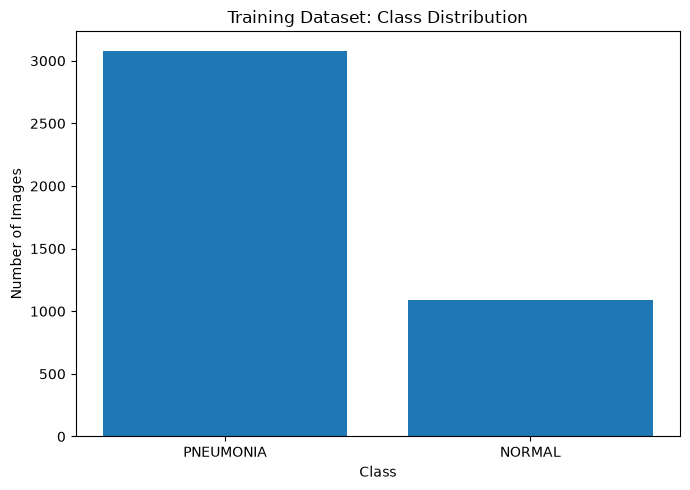

In [20]:
from collections import Counter
import matplotlib.pyplot as plt

def count_classes(dataset, class_names):
    counts = Counter()

    for _, labels in dataset:
        for label in labels.numpy().flatten():
            counts[class_names[int(label)]] += 1

    return counts

class_names = train_ds_raw.class_names

train_counts = count_classes(train_ds_raw, class_names)
val_counts = count_classes(val_ds_raw, class_names)
test_counts = count_classes(test_ds_raw, class_names)

print("Training:", dict(train_counts))
print("Validation:", dict(val_counts))
print("Test:", dict(test_counts))

plt.figure(figsize=(7, 5))
plt.bar(train_counts.keys(), train_counts.values())
plt.title("Training Dataset: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()
